In [8]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
import statsmodels.tsa.api as smt

Сформируем временные ряды:

In [9]:
def get_series(path):
    '''
    Load series data from csv
    :param path: files folder
    :return: Dict(filename: series)
    '''
    folder = Path(path)
    data = {}

    for file in folder.glob('*.csv'):
        df = pd.read_csv(file)

        series = pd.Series(
            df.iloc[:, 1].values,
            index = df.iloc[:, 0],
            name = file.stem
        )

        data[file.stem] = series

    return data

In [10]:
time_series = get_series('../../Series/')

Изобразим графически:

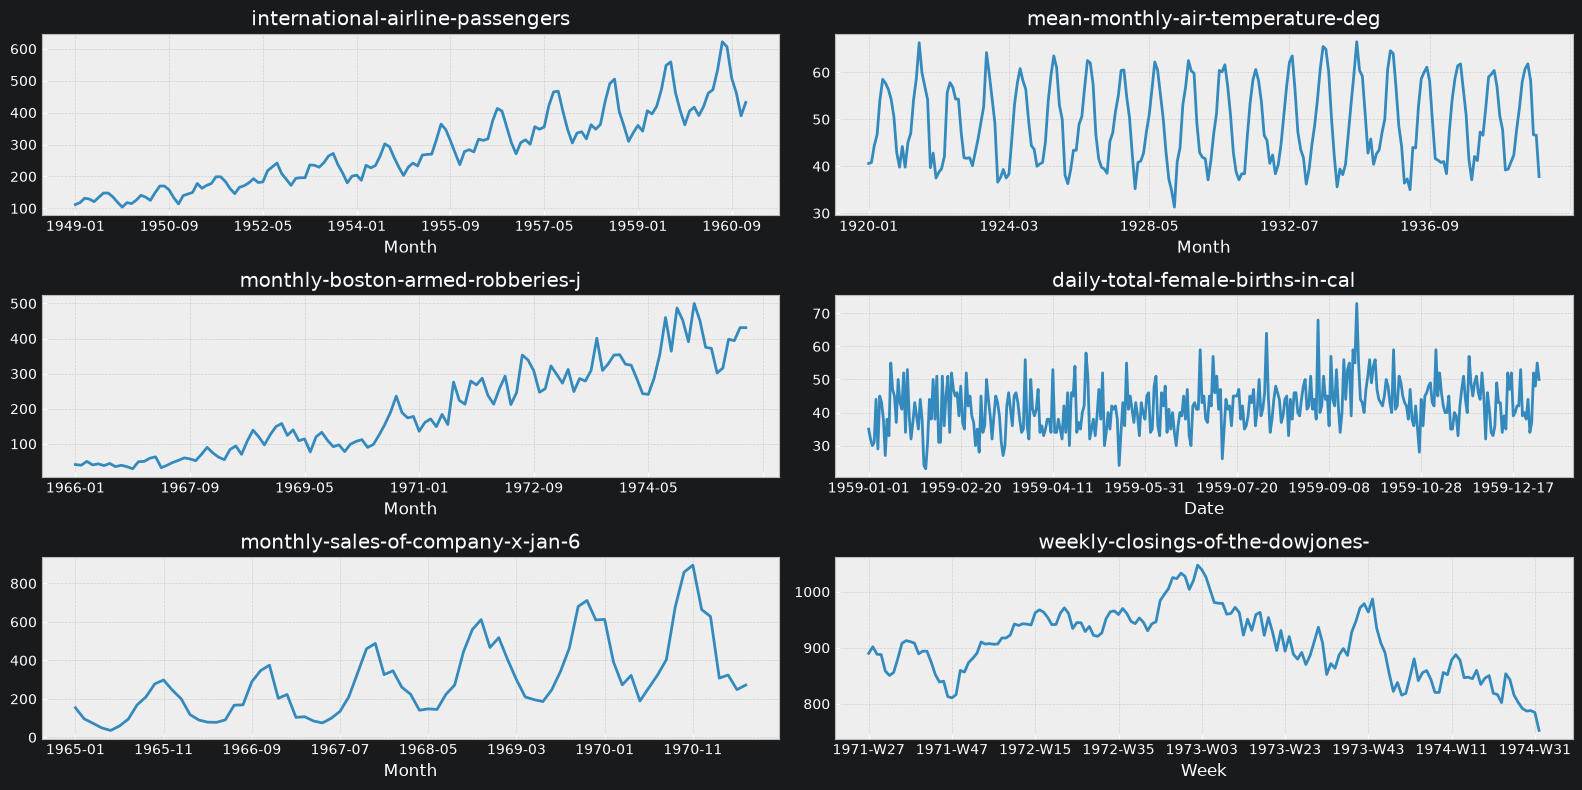

In [12]:
with plt.style.context(style = 'bmh'):
    plt.figure(figsize = (16, 8))
    layout = (3, 2)

    for i, (name, values) in enumerate(time_series.items()):

        x = i % layout[1]
        y = int((i - x) / layout[1])

        ts_ax = plt.subplot2grid(shape = layout, loc = (y, x))
        values.plot(ax = ts_ax)
        ts_ax.set_title(name)

    plt.tight_layout()

plt.show()

# Проверка стационарности по тесту Дики-Фуллера и графикам ACF / PACF:

Выведем графики временных рядов с расчетным значением p_value для теста Дики-Фуллера, а также графики ACF/PACF для проверки свойств стационарности:

In [5]:
def check_series(series, n_cols = 2, width = 12, height = 3, style = 'bmh'):

    names = series.keys()
    n = len(names)

    n_cols = n_cols
    n_rows = (n + n_cols - 1) // n_cols
    n_rows *= 3

    with plt.style.context(style = style):

        fig, axes = plt.subplots(figsize = (n_cols * width, n_rows * height), nrows = n_rows, ncols = n_cols, gridspec_kw = {'height_ratios': [2, 1, 1] * (n_rows // 3)})

        for i, name in enumerate(names):
            x = i % n_cols
            y = ((i - x) * 3) // n_cols

            p = adfuller(x = series[name], autolag = 'AIC', result_object = False)[1]

            series[name].plot(ax = axes[y, x], label = f'p_value = {p:.4f}')
            smt.graphics.plot_acf(x = series[name], ax = axes[y + 1, x])
            smt.graphics.plot_pacf(x = series[name], ax = axes[y + 2, x])

            axes[y, x].legend(loc = 'best', labelcolor = '#000000')

            axes[y, x].set_title(name)

        fig.tight_layout()

        plt.show()

In [6]:
check_series(time_series, n_cols = 3, width = 10, height = 3)

ValueError: Number of rows must be a positive integer, not 0

По тесту Дики-Фуллера стационарными можно признать следующие ряды:<br>
- mean-monthly-air-temperature-deg;
- daily-total-female-births-in-cal.<br/>

Однако, из графиков видно, что только для ряда daily-total-female-births-in-cal свойство стационарности подтверждается резким падением ACF после первого лага.<br/>
Стационарность же ряда mean-monthly-air-temperature-deg не подтверждена графически. Видна его сезонности по годовым интервала 12, 24 и т.д.

# 1. Стабилизация дисперсии (логарифмирование)

<ul>
Если посмотреть на графики, то видно, что амплитуда колебаний отличается у следующих графиков:
<li>weekly-closings-of-the-dowjones-</li>
<li>monthly-boston-armed-robberies-j</li>
<li>monthly-sales-of-company-x-jan-6</li>
<li>international-airline-passengers</li>
</ul>
Применим к ним логарифмирование:

In [ ]:
time_series2 = {name:
                    (
                        np.log(values) if name in ('weekly-closings-of-the-dowjones-',
                                                   'monthly-boston-armed-robberies-j',
                                                   'monthly-sales-of-company-x-jan-6',
                                                   'international-airline-passengers'
                                                   )
                        else values
                    )
                for name, values in time_series.items()
                }

In [ ]:
check_series(time_series2, n_cols = 3, width = 10, height = 3)

Видим, что логарифмирование стабилизировало дисперсию, но не устранило не стационарность. Для устранения стационарности нам необходимы разности.

# 2. Убираем сезонную разность

<ul>У нас имеется один дневной ряд:
<li>daily-total-female-births-in-cal</li>
</ul>
<ul>Один недельный ряд:
<li>weekly-closings-of-the-dowjones-</li>
</ul>
<ul>Четыре месячных ряда:
<li>international-airline-passengers</li>
<li>mean-monthly-air-temperature-deg</li>
<li>monthly-boston-armed-robberies-j</li>
<li>monthly-sales-of-company-x-jan-6</li>
</ul>

<ul>Из графиков ACF видно, что ярко выраженную сезонность имеют месячные графики:
<li>mean-monthly-air-temperature-deg;</li>
<li>monthly-sales-of-company-x-jan-6;</li>
</ul>
Сезонность international-airline-passengers под вопросом.<br/>

Дневной ряд daily-total-female-births-in-cal имеет слабо выраженную недельную сезонность.

Для рядов international-airline-passengers и daily-total-female-births-in-cal уберем сезонную разность и посмотрим, улучшит ли это результат:

In [ ]:
time_series2a = {name:
                    (
                        values.diff(12).dropna() if name == 'international-airline-passengers'
                        else values.diff(7).dropna()
                    )
                for name, values in time_series2.items()
                if name in ('international-airline-passengers', 'daily-total-female-births-in-cal')
                }

In [ ]:
check_series(time_series2a, n_cols = 2, width = 6, height = 2.5)

На графике ACF для рядов видим следующую картину:
- на daily-total-female-births-in-cal имеет провал вниз на 7ом лаге;
- на international-airline-passengers имеет провал вниз на 12ом лаге.

Это показывает, что для этих рядов сезонность отсутствует. Исключим их из сезонной разности.

In [ ]:
time_series3 = {name:
                    (
                        values.diff(12).dropna() if name in ('mean-monthly-air-temperature-deg',
                                                             'monthly-sales-of-company-x-jan-6'
                                                             )
                        else values
                    )
                for name, values in time_series2.items()
                }

In [ ]:
check_series(time_series3, n_cols = 3, width = 10, height = 3)

Из графиков видно, что стационарность ряда mean-monthly-air-temperature-deg теперь также подтверждается графически. На графике ACF первый лаг высокий, а остальные близки к 0.<br/>

# 3. Убираем обычную разность


In [ ]:
time_series4 = {name:
                    (
                        values.diff().dropna() if name in ('weekly-closings-of-the-dowjones-',
                                                           'monthly-boston-armed-robberies-j',
                                                           'monthly-sales-of-company-x-jan-6',
                                                           'international-airline-passengers'
                                                           )
                        else values
                    )
                for name, values in time_series3.items()
                }

In [ ]:
check_series(time_series4, n_cols = 3, width = 10, height = 3)

После избавления от периодичности все ряды, кроме monthly-sales-of-company-x-jan-6 и international-airline-passengers приобрели свойство стационарности. Это подтверждают значения p_value для теста Дики-Фуллера, и графики ACF.<br/>

Для ряда monthly-sales-of-company-x-jan-6 уберем обычную разность после сезонной.<br/>
для ряда international-airline-passengers видим сезонный пик на 12 лаге. Что все же подтверждает сезонность. Уберем ее.

In [ ]:
time_series5 = {name:
                    (
                        values.diff().dropna() if name == 'monthly-sales-of-company-x-jan-6'
                        else values.diff(12).dropna() if name == 'international-airline-passengers'
                        else values
                    )
                for name, values in time_series4.items()
                }

In [ ]:
check_series(time_series5, n_cols = 3, width = 10, height = 3)

Все ряды приобрели свойство стационарности